<a href="https://colab.research.google.com/github/Dewdahara/CRMCM_CW1_w2054873/blob/main/CRMCM_CW1_w2054873.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6BUIS017W CRM & CM with Business Intelligence: Individual Coursework

## Task 1: Data Preparation and Feature Engineering

### Setup

 **Data snapshot update (10 November 2026):** Constituents and daily Close, Adjusted Close and Volume data are stored together in one frozen Excel workbook. Subsequent runs load this workbook and do not refresh Yahoo Finance prices. The benchmark (^GSPC) is included in the price worksheets. The current constituent list remains a point-in-time universe, not a historical membership archive; results are subject to survivorship and constituent-history bias.

In [8]:
# Install the extra packages: yfinance for the prices, lxml so pandas can read the Wikipedia table,
# and seaborn for the charts.
%pip install -q yfinance lxml seaborn

In [9]:
# Import the libraries and record the package versions used in this run.
import os, json, platform, warnings
from datetime import datetime, timezone
from io import StringIO

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display
import scipy
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

PACKAGE_VERSIONS = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "matplotlib": matplotlib.__version__,
    "requests": requests.__version__,
    "seaborn": sns.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__
}
PACKAGE_VERSIONS

{'python': '3.13.18',
 'pandas': '2.2.3',
 'numpy': '2.4.6',
 'yfinance': '0.2.66',
 'matplotlib': '3.10.0',
 'requests': '2.32.4',
 'seaborn': '0.13.2',
 'scipy': '1.16.3',
 'scikit-learn': '1.6.1'}

In [10]:
# Settings for the study period and the data checks. The end date is exclusive, so the last day used
# is 31 Dec 2024.
START_DATE = "2021-01-01"
END_DATE = "2025-01-01"
BENCHMARK = "^GSPC"
BASE_WINDOW = 20
ACTIVITY_WINDOW = 60
HIGH_VOL_MULT = 2.0
MIN_AVAILABILITY = 0.80
MIN_WEEKS = 52

# Prices are never filled in, so dates before a listing stay missing.
FILL_PRICES = False
# Setting this to True downloads fresh constituents and prices and replaces the workbook.
# Once the workbook is saved, set it back to False for every later run.
CREATE_DATA_SNAPSHOT = False
SNAPSHOT_XLSX = "sp500_market_data_snapshot.xlsx"
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

### 1.1 Ticker selection and data acquisition

In [11]:
# Load the saved Excel workbook with the constituents and price history. In a fresh Colab session,
# upload the workbook created earlier.
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

snapshot_loaded = False
if os.path.exists(SNAPSHOT_XLSX) and not CREATE_DATA_SNAPSHOT:
    snapshot_loaded = True
    print("Using existing Excel data snapshot:", SNAPSHOT_XLSX)
else:
    if CREATE_DATA_SNAPSHOT:
        print("CREATE_DATA_SNAPSHOT=True: creating a fresh snapshot; any existing workbook will be replaced.")
    try:
        from google.colab import files
        if not CREATE_DATA_SNAPSHOT:
            print("Upload the previously created sp500_market_data_snapshot.xlsx workbook.")
            uploaded = files.upload()
            for filename, content in uploaded.items():
                if filename.lower().endswith(".xlsx"):
                    with open(SNAPSHOT_XLSX, "wb") as f:
                        f.write(content)
                    snapshot_loaded = True
                    break
    except ImportError:
        pass

if snapshot_loaded:
    constituents = pd.read_excel(SNAPSHOT_XLSX, sheet_name="Constituents")
    metadata_df = pd.read_excel(SNAPSHOT_XLSX, sheet_name="Metadata")
    retrieval_info = dict(zip(metadata_df["key"].astype(str), metadata_df["value"].astype(str)))

    # Rename the constituent columns to the names used below. The workbook can have the original
    # Wikipedia headers or the cleaned ones, with small spacing or case differences.
    original_headers = list(constituents.columns)
    header_lookup = {str(c).strip().lower(): c for c in constituents.columns}
    aliases = {
        "symbol": ["symbol", "ticker", "ticker symbol", "yahoo ticker"],
        "security": ["security", "company", "company name", "name"],
        "gics sector": ["gics sector", "sector", "gics_sector"],
    }
    rename_map = {}
    for target, candidates in aliases.items():
        for candidate in candidates:
            if candidate in header_lookup:
                source_col = header_lookup[candidate]
                if source_col != target:
                    rename_map[source_col] = target
                break
    constituents = constituents.rename(columns=rename_map)
    print("Constituent worksheet columns found:", original_headers)
    print("Constituent columns standardised for analysis:", list(constituents.columns))
    print("Constituents and price data will be loaded from the same frozen workbook.")
else:
    if not CREATE_DATA_SNAPSHOT:
        raise FileNotFoundError(
            f"{SNAPSHOT_XLSX} was not found. Upload the previously created Excel workbook, "
            "or set CREATE_DATA_SNAPSHOT = True for its one-time creation."
        )
    # First-time creation only: get the constituent list here. Prices are downloaded in the next
    # cell.
    resp = requests.get(
        WIKI_URL,
        headers={"User-Agent": "Mozilla/5.0 (university coursework)"},
        timeout=30,
    )
    resp.raise_for_status()
    tables = pd.read_html(StringIO(resp.text))
    constituents = tables[0].copy()
    retrieval_info = {
        "constituents_source": WIKI_URL,
        "constituents_retrieved": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
        "universe_note": "Current S&P 500 constituents retrieved on the recorded date; not historical membership.",
        "price_source": f"Yahoo Finance via yfinance {yf.__version__}; auto_adjust=False",
    }
    print("Retrieved constituent snapshot for one-time Excel workbook creation.")

required_cols = {"symbol", "security", "gics sector"}
assert required_cols.issubset(constituents.columns), (
    f"Constituent data missing required columns: {required_cols - set(constituents.columns)}"
)
assert constituents["symbol"].notna().all(), "Constituent data contains missing ticker symbols."
assert constituents["symbol"].astype(str).is_unique, "Constituent data contains duplicate ticker symbols."

print("Constituents loaded:", len(constituents))
print("Constituent retrieval timestamp:", retrieval_info.get("constituents_retrieved", "Not available"))
print("Universe limitation:", retrieval_info.get("universe_note", "Point-in-time S&P 500 constituents; not historical membership."))

Using existing Excel data snapshot: sp500_market_data_snapshot.xlsx
Constituent worksheet columns found: ['Ticker', 'Company', 'Sector']
Constituent columns standardised for analysis: ['symbol', 'security', 'gics sector']
Constituents and price data will be loaded from the same frozen workbook.
Constituents loaded: 503
Constituent retrieval timestamp: 2026-11-10 17:04 UTC
Universe limitation: Current S&P 500 constituents retrieved on the recorded date; not historical membership.


In [12]:
# Tidy up the constituents table. Tickers with a dot are changed to a dash for Yahoo Finance (BRK.B
# becomes BRK-B). The Excel file itself is not changed.
constituents["Ticker"] = constituents["symbol"].astype(str).str.replace(".", "-", regex=False)
constituents = constituents.rename(columns={"security": "Company", "gics sector": "Sector"})
constituents = constituents[["Ticker", "Company", "Sector"]].drop_duplicates("Ticker").reset_index(drop=True)

tickers = constituents["Ticker"].tolist()
print(f"{len(tickers)} tickers loaded from the frozen Excel snapshot")
print("No live Wikipedia scraping is performed in this cleaning/downstream step.")
display(constituents.head())

# Output:
# 503 tickers are loaded. The first five rows are MMM, AOS, ABT, ABBV and ACN with their company and
# sector.

503 tickers loaded from the frozen Excel snapshot
No live Wikipedia scraping is performed in this cleaning/downstream step.


,Ticker,Company,Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology


In [13]:
# Load the saved price history from the workbook, or download it once when creating the workbook.
if snapshot_loaded:
    prices = {
        "close": pd.read_excel(SNAPSHOT_XLSX, sheet_name="Close", index_col=0, parse_dates=True),
        "adj_close": pd.read_excel(SNAPSHOT_XLSX, sheet_name="Adj_Close", index_col=0, parse_dates=True),
        "volume": pd.read_excel(SNAPSHOT_XLSX, sheet_name="Volume", index_col=0, parse_dates=True),
    }
    print("Historical prices loaded from the uploaded/saved Excel snapshot; Yahoo Finance was not queried.")
else:
    if not CREATE_DATA_SNAPSHOT:
        raise RuntimeError("No frozen Excel snapshot is loaded. Enable CREATE_DATA_SNAPSHOT only for one-time creation.")
    symbols = tickers + [BENCHMARK]
    frames = []
    for batch in np.array_split(symbols, 6):
        block = yf.download(
            [str(s) for s in batch], start=START_DATE, end=END_DATE,
            auto_adjust=False, actions=False, progress=True, threads=True,
        )
        frames.append(block)
    raw = pd.concat(frames, axis=1)
    prices = {"close": raw["Close"], "adj_close": raw["Adj Close"], "volume": raw["Volume"]}

    # Record where and when the data came from.
    retrieval_info["prices_downloaded"] = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    retrieval_info["price_source"] = f"Yahoo Finance via yfinance {yf.__version__}; auto_adjust=False; actions=False"
    retrieval_info["study_start_inclusive"] = START_DATE
    retrieval_info["study_end_exclusive"] = END_DATE
    retrieval_info["benchmark"] = BENCHMARK

    # Save everything into one Excel workbook, one sheet per table.
    metadata_df = pd.DataFrame({"key": list(retrieval_info.keys()), "value": [str(v) for v in retrieval_info.values()]})
    with pd.ExcelWriter(SNAPSHOT_XLSX, engine="openpyxl") as writer:
        constituents.to_excel(writer, sheet_name="Constituents", index=False)
        prices["close"].to_excel(writer, sheet_name="Close", index_label="Date")
        prices["adj_close"].to_excel(writer, sheet_name="Adj_Close", index_label="Date")
        prices["volume"].to_excel(writer, sheet_name="Volume", index_label="Date")
        metadata_df.to_excel(writer, sheet_name="Metadata", index=False)
    print("Created frozen Excel snapshot:", SNAPSHOT_XLSX)
    try:
        from google.colab import files
        files.download(SNAPSHOT_XLSX)
    except ImportError:
        print("Excel snapshot saved in the current working directory.")

# Keep only the constituent tickers and the benchmark.
keep_cols = set(tickers + [BENCHMARK])
for name, df in prices.items():
    df.columns = df.columns.astype(str)
    prices[name] = df.loc[:, [c for c in df.columns if c in keep_cols]]

missing_downloads = sorted(set(tickers) - set(prices["adj_close"].columns))
print("Tickers absent from downloaded price table:", missing_downloads)
print("Price download timestamp:", retrieval_info.get("prices_downloaded", "Not available in workbook"))

Historical prices loaded from the uploaded/saved Excel snapshot; Yahoo Finance was not queried.
Tickers absent from downloaded price table: []
Price download timestamp: 2026-11-10 17:06 UTC


In [14]:
# Check that the three tables cover the right dates and include the benchmark.
for name, df in prices.items():
    print(
        f"{name:10s} shape={df.shape}  first={pd.to_datetime(df.index.min()).date()}  last={pd.to_datetime(df.index.max()).date()}"
    )
print("Benchmark column present:", BENCHMARK in prices["adj_close"].columns)

# Output:
# Each table has 1005 trading days and 504 columns (503 tickers plus the S&P 500 benchmark), running
# from 2021-01-04 to 2024-12-31.
# The benchmark column is there and no 2025 dates are included.

close      shape=(1005, 504)  first=2021-01-04  last=2024-12-31
adj_close  shape=(1005, 504)  first=2021-01-04  last=2024-12-31
volume     shape=(1005, 504)  first=2021-01-04  last=2024-12-31
Benchmark column present: True


### 1.2 Data validation and alignment

In [15]:
# Tidy the date index (no time zone, sorted) and check for duplicate dates. If there are any, the
# first record is kept.
def clean_index(df):
    df = df.copy()
    df.index = pd.to_datetime(df.index)
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)
    return df.sort_index()


close, adj_close, volume = (clean_index(prices[k]) for k in ["close", "adj_close", "volume"])

dup_dates = {
    n: int(d.index.duplicated().sum())
    for n, d in zip(["close", "adj_close", "volume"], [close, adj_close, volume])
}
print("Duplicate dates found:", dup_dates)

close, adj_close, volume = (d[~d.index.duplicated(keep="first")] for d in (close, adj_close, volume))

# Output:
# None of the three tables has duplicate dates.

Duplicate dates found: {'close': 0, 'adj_close': 0, 'volume': 0}


In [16]:
# Split the benchmark from the shares and use its trading days as the common calendar. Every share
# is lined up to that calendar, so missing days show up as NaN and nothing is filled here.
bench = pd.DataFrame(
    {"close": close[BENCHMARK], "adj_close": adj_close[BENCHMARK], "volume": volume[BENCHMARK]}
)
close, adj_close, volume = (d.drop(columns=BENCHMARK) for d in (close, adj_close, volume))

calendar = bench["adj_close"].dropna().index

print("Benchmark trading days:", len(calendar), "|", calendar.min().date(), "to", calendar.max().date())
print("Benchmark non-positive prices:", int((bench[["close", "adj_close"]] <= 0).sum().sum()))
assert calendar.min() >= pd.Timestamp(START_DATE) and calendar.max() < pd.Timestamp(
    END_DATE
), "Data outside study period"

print("Share dates not in benchmark calendar:", len(close.index.difference(calendar)))
close, adj_close, volume = (d.reindex(calendar) for d in (close, adj_close, volume))

# Output:
# The calendar has 1005 trading days (2021-01-04 to 2024-12-31). The benchmark has no zero or
# negative prices and no share has a date outside the calendar.

Benchmark trading days: 1005 | 2021-01-04 to 2024-12-31
Benchmark non-positive prices: 0
Share dates not in benchmark calendar: 0


In [17]:
# Check 1: count the missing values for each share.
missing = pd.DataFrame(
    {
        "missing_close": close.isna().sum(),
        "missing_adj_close": adj_close.isna().sum(),
        "missing_volume": volume.isna().sum(),
    }
)
print("Shares with any missing value:", int((missing.sum(axis=1) > 0).sum()))
display(missing[missing.sum(axis=1) > 0].head(16))

# Output:
# 15 shares have missing values. Five of them (FDXF, HONA, Q, SNDK and VYLR) are missing all 1005
# days because no data came back.
# The other ten are only partly missing because they started trading later: GEV (812 missing days),
# SOLV (811), RDDT (808), VLTO (692), GEHC (492), CEG (263), HOOD (143), APP (70), COIN (69) and EXE
# (26).
# Close, Adj Close and Volume are missing on the same number of days for each share.

Shares with any missing value: 15


,missing_close,missing_adj_close,missing_volume
APP,70,70,70
CEG,263,263,263
COIN,69,69,69
EXE,26,26,26
FDXF,1005,1005,1005
GEHC,492,492,492
GEV,812,812,812
HONA,1005,1005,1005
HOOD,143,143,143
Q,1005,1005,1005


In [18]:
# Check 2: look for prices that are zero or negative.
nonpos = pd.DataFrame({"nonpos_close": (close <= 0).sum(), "nonpos_adj_close": (adj_close <= 0).sum()})
print("Shares with non-positive prices:", int((nonpos.sum(axis=1) > 0).sum()))
display(nonpos[nonpos.sum(axis=1) > 0])

# Output:
# No share has a zero or negative price, so the table is empty.

Shares with non-positive prices: 0


,nonpos_close,nonpos_adj_close


In [19]:
# Check 3: look for zero or negative volume, which is not realistic for an S&P 500 share.
vol_err = pd.DataFrame({"vol_negative": (volume < 0).sum(), "vol_zero": (volume == 0).sum()})
print("Shares with volume errors:", int((vol_err.sum(axis=1) > 0).sum()))
display(vol_err[vol_err.sum(axis=1) > 0])

# Output:
# Two shares have volume problems. FERG has 27 days with zero volume and SW has 424. Neither has
# negative volume.

Shares with volume errors: 2


,vol_negative,vol_zero
FERG,0,27
SW,0,424


In [20]:
# Work out how much price and volume history each share has. Missing values stay missing, and a
# share is flagged if its price or volume availability is below the threshold.
history = pd.DataFrame({
    "n_obs": adj_close.notna().sum(),
    "first_date": adj_close.apply(pd.Series.first_valid_index),
    "last_date": adj_close.apply(pd.Series.last_valid_index),
})
history["availability"] = history["n_obs"] / len(calendar)
history["vol_availability"] = volume.notna().sum() / len(calendar)
AVAIL_THRESHOLD = MIN_AVAILABILITY
history["short_history"] = (history["availability"] < AVAIL_THRESHOLD) | (history["vol_availability"] < AVAIL_THRESHOLD)
print(f"Availability threshold: {AVAIL_THRESHOLD:.0%} of {len(calendar)} benchmark trading days")
print("Shares below threshold:", int(history["short_history"].sum()))
display(history[history["availability"] < 1].sort_values("availability").head(20))

Availability threshold: 80% of 1005 benchmark trading days
Shares below threshold: 11


,n_obs,first_date,last_date,availability,vol_availability,short_history
HONA,0,NaT,NaT,0.0000,0.0000,True
FDXF,0,NaT,NaT,0.0000,0.0000,True
SNDK,0,NaT,NaT,0.0000,0.0000,True
Q,0,NaT,NaT,0.0000,0.0000,True
VYLR,0,NaT,NaT,0.0000,0.0000,True
GEV,193,2024-03-27,2024-12-31,0.1920,0.1920,True
SOLV,194,2024-03-26,2024-12-31,0.1930,0.1930,True
RDDT,197,2024-03-21,2024-12-31,0.1960,0.1960,True
VLTO,313,2023-10-04,2024-12-31,0.3114,0.3114,True
GEHC,513,2022-12-15,2024-12-31,0.5104,0.5104,True


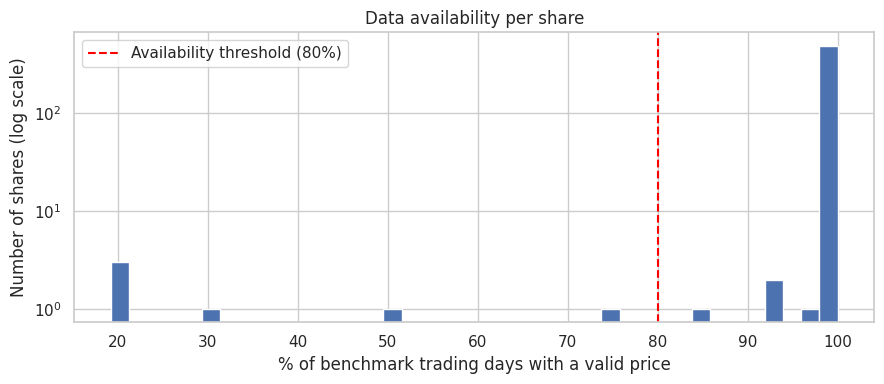

In [21]:
# Chart: how complete each share's price history is, with the availability threshold as a red line.
fig, ax = plt.subplots(figsize=(9, 4))
avail = history.loc[history["n_obs"] > 0, "availability"] * 100
ax.hist(avail, bins=40, color="#4C72B0", edgecolor="white")
ax.axvline(
    AVAIL_THRESHOLD * 100,
    color="red",
    linestyle="--",
    label=f"Availability threshold ({AVAIL_THRESHOLD:.0%})",
)
ax.set_yscale("log")
ax.set_xlabel("% of benchmark trading days with a valid price")
ax.set_ylabel("Number of shares (log scale)")
ax.set_title("Data availability per share")
ax.legend()
plt.tight_layout()
plt.show()

# Output:
# Almost every share sits at about 100%, so the y-axis is on a log scale to make the others visible.
# A few shares sit far to the left (about 20% to 75%) and fail the threshold. A few others between
# about 85% and 97% pass.

In [22]:
# Screen for corporate actions and extreme moves. Close and Adj Close are kept as separate fields:
# Adj Close is used for returns and Close x Volume for traded value. A jump that looks like a split
# is only a flag to review, not proof that the price is unadjusted.
ratio = adj_close / close
ratio_change = ratio / ratio.shift(1) - 1
price_ratio = close / close.shift(1)
extreme = (price_ratio - 1).abs() > 0.40
split_ratios = [1/2, 1/3, 1/4, 1/5, 1/10, 1/20, 2, 3, 4, 5, 10, 20]
split_like = pd.DataFrame(False, index=price_ratio.index, columns=price_ratio.columns)
for r in split_ratios:
    split_like |= (price_ratio / r - 1).abs() < 0.03
corp = pd.DataFrame({
    "dividend_adjustment_steps": (ratio_change.abs() > 1e-4).sum(),
    "ratio_jump_gt_10pct": (ratio_change.abs() > 0.10).sum(),
    "extreme_daily_moves_gt_40pct": extreme.sum(),
    "split_like_events_for_review": split_like.sum(),
})
corp.to_csv(f"{DATA_DIR}/corporate_action_checks.csv")

# Only add a ticker to this list after checking its corporate-action record and confirming the price
# series really has an unadjusted split.
CONFIRMED_UNADJUSTED_SPLIT_TICKERS = []
print("Shares with split-like events requiring review:", int((corp["split_like_events_for_review"] > 0).sum()))
print("Confirmed unadjusted split tickers excluded:", CONFIRMED_UNADJUSTED_SPLIT_TICKERS)
print("Shares with >40% daily price moves requiring review:", int((corp["extreme_daily_moves_gt_40pct"] > 0).sum()))
display(corp[(corp["split_like_events_for_review"] > 0) | (corp["ratio_jump_gt_10pct"] > 0) | (corp["extreme_daily_moves_gt_40pct"] > 0)])

Shares with split-like events requiring review: 0
Confirmed unadjusted split tickers excluded: []
Shares with >40% daily price moves requiring review: 7


,dividend_adjustment_steps,ratio_jump_gt_10pct,extreme_daily_moves_gt_40pct,split_like_events_for_review
APP,0,0,1,0
BE,0,0,1,0
CVNA,0,0,5,0
DXCM,0,0,1,0
GL,16,0,1,0
HOOD,0,0,1,0
RDDT,0,0,1,0


In [23]:
# List every day with a price move bigger than 40% so each one can be reviewed. They are kept unless
# they look like a split.
rows = []
for t in extreme.columns[extreme.any()]:
    for d in extreme.index[extreme[t]]:
        rows.append({"Ticker": t, "Date": d.date(), "Daily_price_move": price_ratio.loc[d, t] - 1})
display(pd.DataFrame(rows))

# Output:
# There are 11 such days across 7 shares: APP, BE, CVNA (5 days), DXCM, GL, HOOD and RDDT.
# The biggest gain is BE at +59% on 2024-11-15 and the biggest drop is GL at -53% on 2024-04-11.
# None of them matches a split ratio, so they are treated as real price moves and kept.

,Ticker,Date,Daily_price_move
0,APP,2024-11-07,0.4627
1,BE,2024-11-15,0.5919
2,CVNA,2022-08-05,0.4007
3,CVNA,2022-12-07,-0.4292
4,CVNA,2023-01-12,0.4600
5,CVNA,2023-06-08,0.5602
6,CVNA,2023-07-19,0.4020
7,DXCM,2024-07-26,-0.4066
8,GL,2024-04-11,-0.5314
9,HOOD,2021-08-04,0.5041


In [24]:
# Build the inclusion/exclusion log (the evidence tables and charts are in section 1.5.1). A share
# is kept only if it has data, at least 80% price and volume availability, positive prices, valid
# volume, no confirmed unadjusted split and a complete final 80-session window. Prices are not
# filled in.
RFM_HISTORY = BASE_WINDOW + ACTIVITY_WINDOW
recent = pd.DataFrame({
    "recent_missing": adj_close.iloc[-RFM_HISTORY:].isna().sum()
        + close.iloc[-RFM_HISTORY:].isna().sum()
        + volume.iloc[-RFM_HISTORY:].isna().sum()
})
checks = pd.concat([
    missing, nonpos, vol_err,
    history[["n_obs", "availability", "vol_availability"]], corp, recent
], axis=1).reindex(tickers)
no_data = checks["n_obs"].isna() | (checks["n_obs"] == 0)

rules = pd.DataFrame({
    "R1 no data downloaded": no_data,
    "R2 below availability threshold": ~no_data & ((checks["availability"] < AVAIL_THRESHOLD) | (checks["vol_availability"] < AVAIL_THRESHOLD)),
    "R3 non-positive price": (checks[["nonpos_close", "nonpos_adj_close"]] > 0).any(axis=1),
    "R4 volume error": (checks[["vol_negative", "vol_zero"]] > 0).any(axis=1),
    "R5 confirmed unadjusted split": checks.index.to_series().isin(CONFIRMED_UNADJUSTED_SPLIT_TICKERS).to_numpy(),
    "R6 gaps in latest 80 sessions": ~no_data & (checks["recent_missing"] > 0),
})
R = {c.split()[0]: c for c in rules.columns}
log = constituents.set_index("Ticker").copy()
log["exclusion_reason"] = rules.apply(lambda r: "; ".join(r.index[r.to_numpy()]), axis=1)
log["included"] = log["exclusion_reason"] == ""
valid_tickers = log.index[log["included"]].tolist()
print(f"Included after validation: {len(valid_tickers)} | excluded: {int((~log["included"]).sum())}")

Included after validation: 490 | excluded: 13


In [25]:
# Summarise the exclusions by reason and list the excluded shares.
display(log.loc[~log["included"], "exclusion_reason"].value_counts().to_frame("shares"))
display(log.loc[~log["included"], ["Company", "Sector", "exclusion_reason"]].head(18))

# Output:
# 6 shares fail R2 (availability below 80%), 5 fail R1 (no data) and 2 fail R4 (volume errors: FERG
# and SW).
# Most of the excluded shares are recent spin-offs or listings, for example GEV, SOLV, GEHC, VLTO,
# RDDT and CEG.
# Only today's index members are used, so companies that left the index since 2021 are missing. This
# is survivorship bias, so the results describe the survivors only.

,shares
exclusion_reason,
R2 below availability threshold,6
R1 no data downloaded,5
R4 volume error,2


,Company,Sector,exclusion_reason
Ticker,,,
CEG,Constellation Energy,Utilities,R2 below availability threshold
FDXF,FedEx Freight,Industrials,R1 no data downloaded
FERG,Ferguson Enterprises,Industrials,R4 volume error
GEHC,GE HealthCare,Health Care,R2 below availability threshold
GEV,GE Vernova,Industrials,R2 below availability threshold
HONA,Honeywell Aerospace,Industrials,R1 no data downloaded
Q,Qnity Electronics,Information Technology,R1 no data downloaded
RDDT,Reddit,Communication Services,R2 below availability threshold
SNDK,Sandisk,Information Technology,R1 no data downloaded


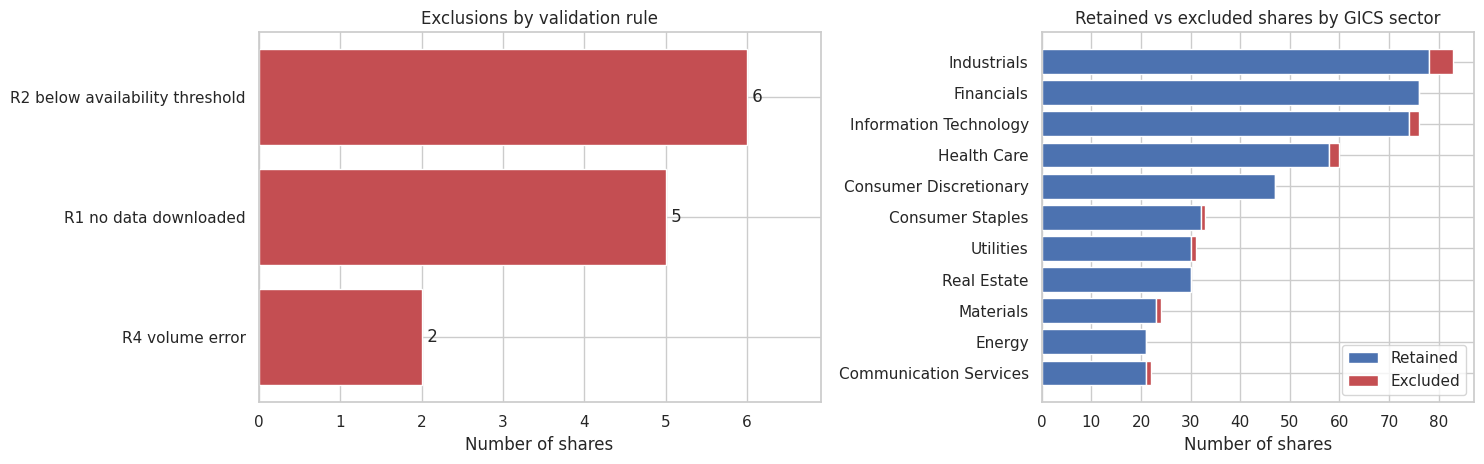

In [26]:
# Chart: number of exclusions for each rule (left) and retained vs excluded shares for each GICS
# sector (right).
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})

reason_counts = rules.sum().sort_values()
reason_counts = reason_counts[reason_counts > 0]
if len(reason_counts):
    axes[0].barh(reason_counts.index, reason_counts.values, color="#C44E52")
    for y, v in enumerate(reason_counts.values):
        axes[0].text(v, y, f" {v}", va="center")
axes[0].set_xlim(0, (reason_counts.max() if len(reason_counts) else 1) * 1.15)
axes[0].set_title("Exclusions by validation rule")
axes[0].set_xlabel("Number of shares")

sector_counts = (
    log.groupby(["Sector", "included"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={True: "Retained", False: "Excluded"})
)
sector_counts = sector_counts.reindex(columns=["Retained", "Excluded"], fill_value=0)
sector_counts = sector_counts.sort_values("Retained")
axes[1].barh(sector_counts.index, sector_counts["Retained"], color="#4C72B0", label="Retained")
axes[1].barh(
    sector_counts.index,
    sector_counts["Excluded"],
    left=sector_counts["Retained"],
    color="#C44E52",
    label="Excluded",
)
axes[1].set_title("Retained vs excluded shares by GICS sector")
axes[1].set_xlabel("Number of shares")
axes[1].legend()
plt.tight_layout()
plt.show()

# Output:
# Left chart: 6 shares for R2, 5 for R1 and 2 for R4.
# Right chart: Industrials loses the most shares (5: FDXF, FERG, GEV, HONA and VLTO). Health Care
# (GEHC, SOLV) and Information Technology (Q, SNDK) lose 2 each. Consumer Staples (VYLR), Utilities
# (CEG), Communication Services (RDDT) and Materials (SW) lose 1 each, and Energy, Financials,
# Consumer Discretionary and Real Estate lose none.

In [27]:
# Keep the observed prices exactly as downloaded. No forward-fill or back-fill is used (FILL_PRICES
# = False), so every missing value stays NaN. Close and Adj Close should be missing on exactly the
# same days.
assert not FILL_PRICES, "Price imputation must remain disabled"
close_v = close[valid_tickers].copy()
adj_close_v = adj_close[valid_tickers].copy()
volume_v = volume[valid_tickers].copy()

missingness_difference = int((close_v.isna() != adj_close_v.isna()).to_numpy().sum())
print("Close vs Adj Close missingness disagreements (investigate if non-zero):", missingness_difference)
print("Validated raw price shape:", close_v.shape)
print("Shares with missing historical prices retained as NaN:", int(adj_close_v.isna().any().sum()))

Close vs Adj Close missingness disagreements (investigate if non-zero): 0
Validated raw price shape: (1005, 490)
Shares with missing historical prices retained as NaN: 4


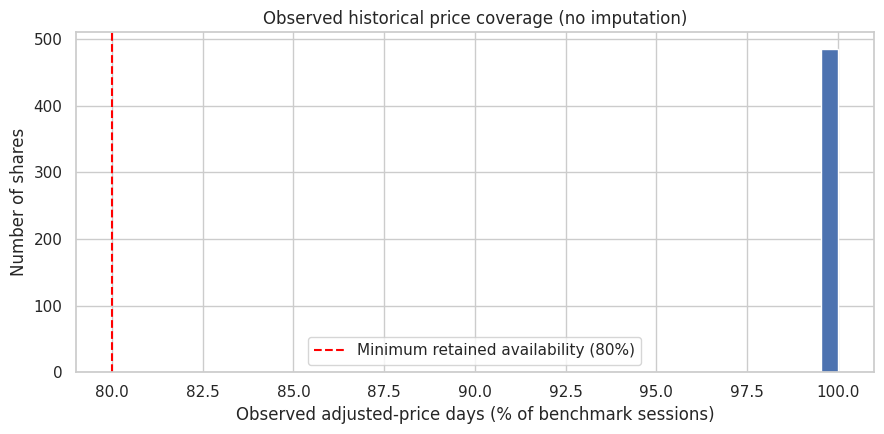

In [28]:
# Chart: price coverage for the retained shares. No prices are filled in.
coverage = adj_close_v.notna().mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(coverage * 100, bins=30, edgecolor="white")
ax.axvline(AVAIL_THRESHOLD * 100, color="red", linestyle="--", label=f"Minimum retained availability ({AVAIL_THRESHOLD:.0%})")
ax.set_xlabel("Observed adjusted-price days (% of benchmark sessions)")
ax.set_ylabel("Number of shares")
ax.set_title("Observed historical price coverage (no imputation)")
ax.legend()
plt.tight_layout()
plt.show()

### 1.3 Weekly return and weekly beta

In [29]:
# Friday-ending weekly prices, using the last available trading price in each week. Weeks before a
# listing stay missing, and incomplete first or last weeks are dropped.
weekly_adj = adj_close_v.resample("W-FRI").last()
weekly_bench = bench["adj_close"].resample("W-FRI").last()
week_end = weekly_adj.index
week_start = week_end - pd.Timedelta(days=4)
complete = (week_start >= pd.Timestamp(START_DATE)) & (week_end < pd.Timestamp(END_DATE))
print("Incomplete weeks dropped:", [d.date().isoformat() for d in week_end[~complete]])
weekly_adj, weekly_bench = weekly_adj.loc[complete], weekly_bench.loc[complete]
print("Missing weekly prices across retained shares:", int(weekly_adj.isna().sum().sum()), "| benchmark:", int(weekly_bench.isna().sum()))
print("Weekly price labels:", len(weekly_adj), "from", weekly_adj.index.min().date(), "to", weekly_adj.index.max().date())

Incomplete weeks dropped: ['2025-01-03']
Missing weekly prices across retained shares: 62 | benchmark: 0
Weekly price labels: 208 from 2021-01-08 to 2024-12-27


In [30]:
# Weekly returns are only worked out from two valid weekly prices next to each other.
# fill_method=None stops pandas carrying an old price over a missing week, which would give a false
# return.
weekly_ret = weekly_adj.pct_change(fill_method=None).iloc[1:]
bench_ret = weekly_bench.pct_change(fill_method=None).iloc[1:]
common_weeks = weekly_ret.index.intersection(bench_ret.index)
weekly_ret, bench_ret = weekly_ret.loc[common_weeks], bench_ret.loc[common_weeks]
assert weekly_ret.index.equals(bench_ret.index)

weekly_obs = weekly_ret.count()
print("Common weekly labels:", len(common_weeks))
print("Per-share valid adjacent weekly returns: min / median / max =",
      int(weekly_obs.min()), int(weekly_obs.median()), int(weekly_obs.max()))
print("Benchmark valid weekly returns:", int(bench_ret.notna().sum()))
print("Benchmark Close and Adj Close identical:", bool(np.allclose(bench["close"], bench["adj_close"], equal_nan=True)))

Common weekly labels: 207
Per-share valid adjacent weekly returns: min / median / max = 178 207 207
Benchmark valid weekly returns: 207
Benchmark Close and Adj Close identical: True


#### 1.3.1 Mean weekly return

In [31]:
# Mean weekly return for each share: the average of its observed weekly returns.
mean_weekly_return = weekly_ret.mean(axis=0, skipna=True)
n_weeks = weekly_ret.count()
assert (n_weeks >= MIN_WEEKS).all(), "A retained share has fewer than MIN_WEEKS valid weekly returns"
for t in weekly_ret.columns:
    assert np.isclose(mean_weekly_return[t], weekly_ret[t].dropna().mean())
print("Valid weekly observations per share: min / median / max =", int(n_weeks.min()), int(n_weeks.median()), int(n_weeks.max()))
display(mean_weekly_return.describe().to_frame("mean_weekly_return"))

Valid weekly observations per share: min / median / max = 178 207 207


,mean_weekly_return
count,490.0000
mean,0.0029
std,0.0027
min,-0.0045
25%,0.0012
50%,0.0027
75%,0.0043
max,0.0178


#### 1.3.2 Weekly beta

In [32]:
# Function for weekly beta: Cov(share, market) / Var(market), using only the weeks where both
# returns exist (at least 52 weeks needed). Then calculate the beta of every share.
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    results = []
    for share in weekly_returns.columns:
        paired = pd.concat([weekly_returns[share].rename("share"), market_returns.rename("market")], axis=1)
        paired = paired.replace([np.inf, -np.inf], np.nan).dropna()
        variance = paired["market"].var(ddof=1)
        beta_value = np.nan
        if len(paired) >= min_weeks and variance > 0:
            beta_value = paired["share"].cov(paired["market"]) / variance
        results.append({"Share": share, "Beta": beta_value, "Paired_weeks": len(paired)})
    return pd.DataFrame(results, columns=["Share", "Beta", "Paired_weeks"]).set_index("Share")


beta_df = calculate_weekly_beta(weekly_ret, bench_ret, min_weeks=MIN_WEEKS)
beta = beta_df["Beta"]

print("Paired weekly observations used for beta (unique values):", beta_df["Paired_weeks"].unique())
print("Shares without a beta (fewer than MIN_WEEKS paired weeks):", int(beta.isna().sum()))
display(beta.describe().to_frame("weekly_beta"))

# Output:
# Every share has at least 178 paired weekly returns (207 for most), well above the 52-week minimum,
# so all 490 shares get a beta.
# The average beta is 0.98 and the median is 0.95. The range is 0.06 to 3.78 and 75% of the shares
# are below 1.19.

Paired weekly observations used for beta (unique values): [207 193 202 178]
Shares without a beta (fewer than MIN_WEEKS paired weeks): 0


,weekly_beta
count,490.0000
mean,0.9823
std,0.4229
min,0.0555
25%,0.6678
50%,0.9547
75%,1.1886
max,3.7786


In [33]:
# Two extra checks on beta using the same paired weeks: the covariance/variance version and an OLS
# slope.
vectorised = pd.Series({t: weekly_ret[t].cov(bench_ret) / bench_ret[weekly_ret[t].notna()].var() for t in weekly_ret.columns})
ols_slope = {}
for t in weekly_ret.columns:
    paired = pd.concat([weekly_ret[t], bench_ret], axis=1).dropna()
    ols_slope[t] = np.polyfit(paired.iloc[:, 1].to_numpy(), paired.iloc[:, 0].to_numpy(), 1)[0]
ols_slope = pd.Series(ols_slope)
print("Beta matches pairwise Cov/Var:", bool(np.allclose(beta, vectorised, equal_nan=True)))
print("Beta matches pairwise OLS slope:", bool(np.allclose(beta, ols_slope, equal_nan=True)))

Beta matches pairwise Cov/Var: True
Beta matches pairwise OLS slope: True


In [34]:
# Put the benchmark return next to the share returns to see the weekly data the betas are calculated
# from.
beta_input_dataset = weekly_ret.copy()
beta_input_dataset.insert(0, "S&P 500 Benchmark (^GSPC)", bench_ret)

print(f"Dataset Shape: {beta_input_dataset.shape} (Weeks x Assets)")
display(beta_input_dataset.head(10))

# Output:
# The table has 207 weeks and 491 columns (the benchmark plus 490 shares). In the first week shown
# (2021-01-15) the benchmark fell by 1.48%.

Dataset Shape: (207, 491) (Weeks x Assets)


,S&P 500 Benchmark (^GSPC),MMM,AOS,ABT,ABBV,ACN,ADBE,AMD,AES,AFL,A,APD,ABNB,AKAM,ALB,...,WELL,WST,WDC,WY,WSM,WMB,WTW,WDAY,WYNN,XEL,XYL,YUM,ZBRA,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01-15,-0.0148,-0.0064,0.0119,0.0012,0.0423,-0.0365,-0.0557,-0.0674,0.0858,0.0447,-0.0067,0.0041,0.1302,0.0289,-0.0215,...,0.0250,-0.0264,-0.0118,-0.0258,0.1573,0.0563,0.0148,-0.0224,-0.0257,-0.0122,-0.0361,-0.0049,0.0092,0.0074,-0.0390
2021-01-22,0.0194,0.0211,0.0164,0.0138,0.0031,0.0044,0.0313,0.0519,-0.0181,-0.0011,0.0010,-0.0115,0.0744,0.0245,-0.0357,...,-0.0184,0.0028,-0.0098,0.0212,0.0641,-0.0400,-0.0007,0.0583,0.0115,-0.0031,-0.0087,0.0044,-0.0009,0.0056,0.0125
2021-01-29,-0.0331,0.0392,-0.0553,0.0953,-0.0756,-0.0504,-0.0289,-0.0771,-0.0940,-0.0269,-0.0488,-0.0594,0.0097,0.0181,-0.0636,...,-0.0392,-0.0020,0.1128,-0.0608,-0.0257,-0.0171,-0.0172,-0.0340,-0.0737,-0.0119,-0.0586,-0.0523,-0.0514,-0.0456,-0.0556
2021-02-05,0.0465,0.0191,0.1050,0.0036,0.0610,0.0480,0.0727,0.0264,0.1013,0.0060,0.0250,-0.0510,0.0636,0.0328,-0.0338,...,0.0564,-0.0272,0.0587,0.1029,-0.0013,0.0405,0.1033,0.1601,0.1754,-0.0086,0.0166,0.0379,0.0497,0.0405,0.0326
2021-02-12,0.0123,0.0065,0.0062,0.0339,-0.0395,0.0155,0.0137,0.0668,0.0622,0.0323,0.0390,0.0292,0.0889,-0.1141,0.0475,...,0.0545,0.0091,0.0976,0.0186,-0.0166,0.0340,0.0157,0.0660,0.0074,-0.0299,0.0095,0.0060,0.1735,0.0093,0.0466
2021-02-19,-0.0071,-0.0121,-0.0121,-0.0405,0.0055,-0.0124,-0.0395,-0.0447,-0.0077,0.0320,-0.0087,0.0128,-0.0546,-0.0269,-0.0514,...,0.0222,-0.0424,0.0505,-0.0014,0.0254,-0.0088,-0.0107,-0.0178,0.0493,0.0086,0.0091,-0.0032,0.0276,-0.0292,-0.0402
2021-02-26,-0.0245,-0.0084,-0.0045,-0.0265,0.0260,-0.0133,-0.0406,-0.0566,-0.0618,-0.0040,-0.0378,-0.0313,0.0263,-0.0441,0.0067,...,-0.0072,-0.0032,-0.0051,-0.0320,0.0112,0.0088,-0.0193,-0.1128,0.0653,-0.0561,-0.0018,-0.0152,0.0173,0.0408,-0.0297
2021-03-05,0.0081,0.0328,0.0524,-0.0211,-0.0097,-0.0055,-0.0410,-0.0709,-0.0215,0.0430,-0.0486,0.0321,-0.1286,0.0278,-0.0848,...,0.0348,-0.0650,-0.0067,0.0018,-0.0238,0.0622,0.0334,-0.0333,0.0121,0.0471,0.0068,0.0077,-0.0426,-0.0280,-0.0616
2021-03-12,0.0264,0.0228,0.0304,-0.0046,0.0142,0.0619,0.0079,0.0322,0.0947,0.0378,0.0456,0.0358,0.1498,0.0043,0.0959,...,0.0549,0.0447,0.0059,0.0637,0.0539,0.0033,-0.0231,0.0663,0.0280,0.0194,0.0163,0.0046,-0.0111,0.0294,0.0473


In [35]:
# Turn the weekly return table into a long table (one row per share per week), attach each share's
# beta, then check for missing values.
combined_df = (
    weekly_ret.rename_axis(index="Week", columns="Share")
    .reset_index()
    .melt(id_vars="Week", var_name="Share", value_name="Weekly_Return")
    .join(beta, on="Share")
    .sort_values(["Share", "Week"])
    .reset_index(drop=True)
)
print("Null values per column:")
print(combined_df.isna().sum())

rows_before = len(combined_df)
combined_df = combined_df.dropna().reset_index(drop=True)
print("Rows removed:", rows_before - len(combined_df), "| Rows remaining:", len(combined_df))
combined_df.to_csv(f"{DATA_DIR}/weekly_returns_long.csv", index=False)
combined_df.head()

# Output:
# 62 weekly returns are missing, so 62 rows were removed and 101,368 rows remain (490 shares x 207
# weeks = 101,430, minus 62). Share A, for example, has a beta of 1.0747.

Null values per column:
Week              0
Share             0
Weekly_Return    62
Beta              0
dtype: int64
Rows removed: 62 | Rows remaining: 101368


,Week,Share,Weekly_Return,Beta
0,2021-01-15,A,-0.0067,1.0747
1,2021-01-22,A,0.0010,1.0747
2,2021-01-29,A,-0.0488,1.0747
3,2021-02-05,A,0.0250,1.0747
4,2021-02-12,A,0.0390,1.0747


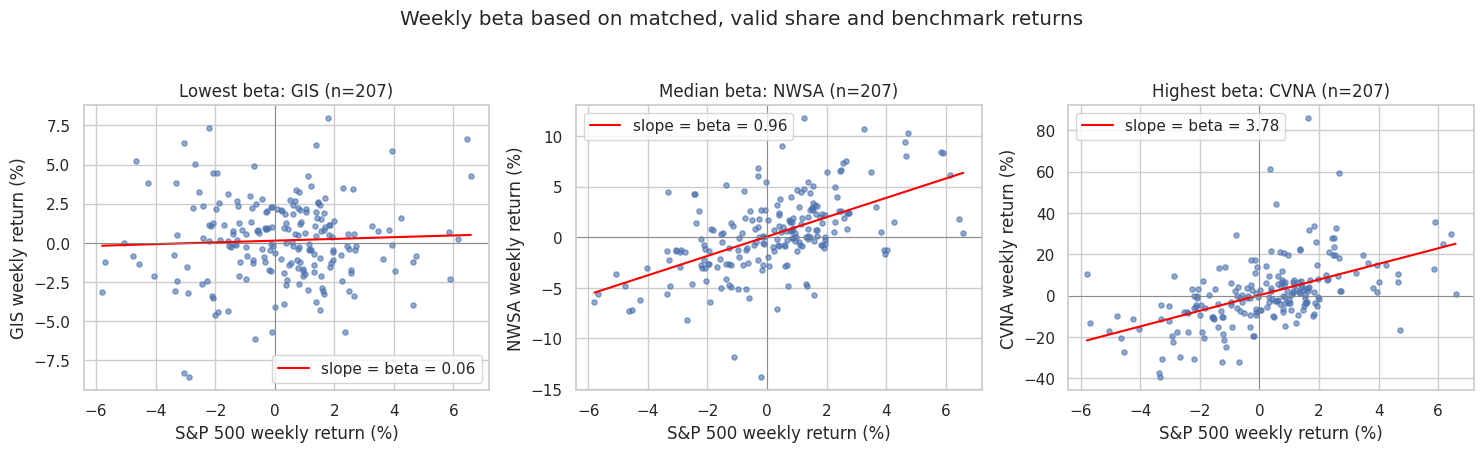

In [36]:
# Chart: the shares with the lowest, median and highest beta, each plotted against the market using
# matched weekly returns.
b = beta.dropna()
pick = {"Lowest beta": b.idxmin(), "Median beta": (b - b.median()).abs().idxmin(), "Highest beta": b.idxmax()}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True)
for ax, (label, t) in zip(axes, pick.items()):
    paired = pd.concat([weekly_ret[t].rename("share"), bench_ret.rename("market")], axis=1).dropna()
    x, y = paired["market"].to_numpy(), paired["share"].to_numpy()
    intercept = y.mean() - beta[t] * x.mean()
    xs = np.linspace(x.min(), x.max(), 50)
    ax.scatter(x * 100, y * 100, s=14, alpha=0.6)
    ax.plot(xs * 100, (intercept + beta[t] * xs) * 100, color="red", label=f"slope = beta = {beta[t]:.2f}")
    ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
    ax.set_title(f"{label}: {t} (n={len(paired)})")
    ax.set_xlabel("S&P 500 weekly return (%)"); ax.set_ylabel(f"{t} weekly return (%)")
    ax.legend()
fig.suptitle("Weekly beta based on matched, valid share and benchmark returns")
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

In [39]:
# Check how many valid weekly returns each share has and confirm the gaps are not filled.
weekly_coverage = pd.DataFrame({
    "valid_weekly_returns": weekly_ret.count(),
    "missing_weekly_returns": weekly_ret.isna().sum(),
    "first_valid_week": weekly_ret.apply(pd.Series.first_valid_index),
    "last_valid_week": weekly_ret.apply(pd.Series.last_valid_index),
})
weekly_coverage.to_csv(f"{DATA_DIR}/weekly_return_coverage.csv")
display(weekly_coverage.sort_values("valid_weekly_returns").head(15))
assert weekly_coverage["valid_weekly_returns"].ge(MIN_WEEKS).all()

,valid_weekly_returns,missing_weekly_returns,first_valid_week,last_valid_week
HOOD,178,29,2021-08-06,2024-12-27
COIN,193,14,2021-04-23,2024-12-27
APP,193,14,2021-04-23,2024-12-27
EXE,202,5,2021-02-19,2024-12-27
WSM,207,0,2021-01-15,2024-12-27
WY,207,0,2021-01-15,2024-12-27
WDC,207,0,2021-01-15,2024-12-27
WST,207,0,2021-01-15,2024-12-27
WELL,207,0,2021-01-15,2024-12-27
WFC,207,0,2021-01-15,2024-12-27


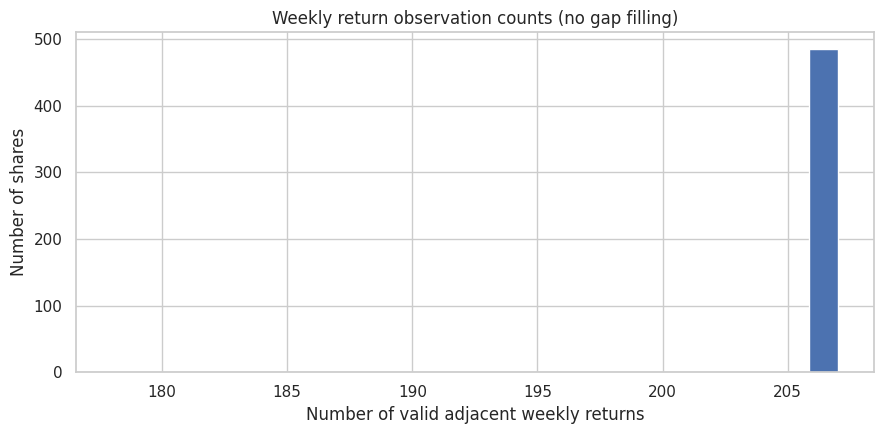

In [40]:
# Chart: number of valid weekly returns per share. Missing weeks are unavailable data, not zero
# returns.
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(weekly_coverage["valid_weekly_returns"], bins=25, edgecolor="white")
ax.set_xlabel("Number of valid adjacent weekly returns")
ax.set_ylabel("Number of shares")
ax.set_title("Weekly return observation counts (no gap filling)")
plt.tight_layout(); plt.show()

### 1.4 Adapted RFM calculations

In [41]:
# Find the last date where every retained share and the benchmark have data (the observation date)
# and the latest 60 trading sessions up to it. The final 80-session check in 1.2 already guarantees
# these windows are complete.
common_dates = close_v.dropna(how="any").index.intersection(adj_close_v.dropna(how="any").index).intersection(bench["adj_close"].dropna().index)
observation_date = common_dates.max()
window_dates = calendar[calendar <= observation_date][-ACTIVITY_WINDOW:]
assert len(window_dates) == ACTIVITY_WINDOW
assert close_v.loc[window_dates].notna().all().all()
assert adj_close_v.loc[window_dates].notna().all().all()
assert volume_v.loc[window_dates].notna().all().all()
print("Observation date:", observation_date.date())
print(f"Latest {ACTIVITY_WINDOW} trading sessions:", window_dates.min().date(), "to", window_dates.max().date())

Observation date: 2024-12-31
Latest 60 trading sessions: 2024-10-07 to 2024-12-31


In [42]:
# Flag the high-volume days. A day counts as an event when its volume is more than 2 times the
# average of the previous 20 sessions (the day being tested is left out of that average).
vol = volume_v.loc[:observation_date]
baseline = vol.rolling(BASE_WINDOW).mean().shift(1)
threshold = HIGH_VOL_MULT * baseline
event = vol > threshold

print("Total high-volume events flagged:", int(event.sum().sum()))

# Output:
# 18,494 high-volume share-days are flagged across the 490 retained shares. The first 20 sessions of
# the sample have no baseline, so no event can be flagged there.
# The rule is rebuilt separately and tested in section 1.5.2.

Total high-volume events flagged: 18494


In [43]:
# Check the event flags against a direct calculation for a sample of retained shares.
assert len(vol) >= BASE_WINDOW + ACTIVITY_WINDOW
assert baseline.loc[window_dates].notna().all().all(), "Baseline missing inside the final 60-session window"
rng = np.random.default_rng(42)
for t in rng.choice(event.columns, min(3, len(event.columns)), replace=False):
    v = vol[t].to_numpy(dtype=float)
    valid = vol[t].notna().to_numpy()
    naive = np.zeros(len(v), dtype=bool)
    for i in range(BASE_WINDOW, len(v)):
        prev = v[i-BASE_WINDOW:i]
        naive[i] = valid[i] and np.isfinite(prev).all() and v[i] > HIGH_VOL_MULT * prev.mean()
    assert np.array_equal(naive, event[t].fillna(False).to_numpy()), f"Mismatch for {t}"
print("Manual rolling-threshold checks passed: preceding 20 sessions only; no look-ahead.")

Manual rolling-threshold checks passed: preceding 20 sessions only; no look-ahead.


#### 1.4.1 Recency

In [44]:
# Recency: find the date of each share's latest high-volume day and count the calendar days from
# there to the observation date. A share with no event would get a missing value, not 0.
last_event_date = pd.to_datetime(
    pd.Series(
        {t: (event.index[event[t].to_numpy()].max() if event[t].any() else pd.NaT) for t in event.columns}
    )
)

recency = (observation_date - last_event_date).dt.days

print("Shares with no event (Recency missing):", int(recency.isna().sum()))
print("Shares with an event on the observation date (R = 0):", int((recency == 0).sum()))
display(recency.describe().to_frame("Recency"))

# Output:
# Every share had at least one high-volume day (0 missing) and none had one on 2024-12-31 (0 with R
# = 0).
# The smallest Recency is 4 days, the median is 11 days and the largest is 222 days (one share that
# last spiked about 7 months before the end).
# The median equals the 25th percentile (11) because many shares have the same latest spike date, as
# the next chart shows.

Shares with no event (Recency missing): 0
Shares with an event on the observation date (R = 0): 0


,Recency
count,490.0000
mean,20.5122
std,21.3432
min,4.0000
25%,11.0000
50%,11.0000
75%,17.2500
max,222.0000


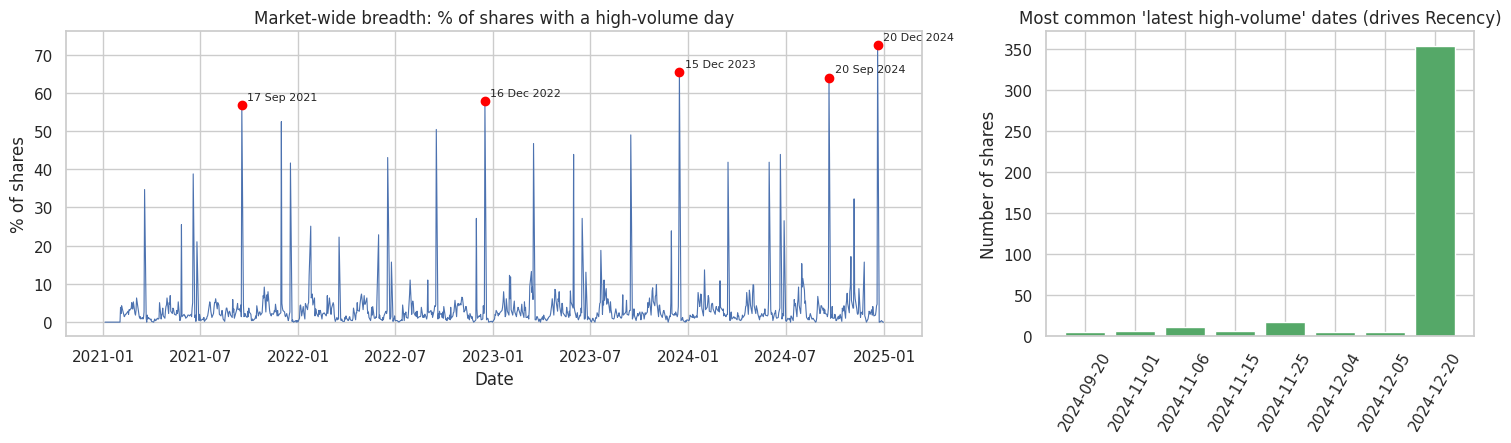

In [45]:
# Chart: percentage of shares with a high-volume day on each date (left, five busiest days marked)
# and the most common latest high-volume dates, which drive Recency (right).
breadth = event.sum(axis=1) / event.shape[1] * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [2, 1]})

axes[0].plot(breadth.index, breadth.values, lw=0.8, color="#4C72B0")
for d, v in breadth.nlargest(5).items():
    axes[0].scatter(d, v, color="red", zorder=3)
    axes[0].annotate(d.strftime("%d %b %Y"), (d, v), textcoords="offset points", xytext=(4, 4), fontsize=8)
axes[0].set_title("Market-wide breadth: % of shares with a high-volume day")
axes[0].set_ylabel("% of shares")
axes[0].set_xlabel("Date")

last_counts = last_event_date.dt.strftime("%Y-%m-%d").value_counts().head(8).sort_index()
axes[1].bar(last_counts.index, last_counts.values, color="#55A868")
axes[1].set_title("Most common 'latest high-volume' dates (drives Recency)")
axes[1].set_ylabel("Number of shares")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

# Output:
# The spikes in the left chart are market-wide days when about 57% to 72% of shares had a
# high-volume day at once.
# The five busiest are 17 Sep 2021, 16 Dec 2022, 15 Dec 2023, 20 Sep 2024 and 20 Dec 2024. All of
# them are the third Friday of a quarter-end month, so this looks like quarterly options expiry and
# index rebalancing, although the data does not prove it.
# On the right, about 350 shares have 2024-12-20 as their latest spike, which is why most Recency
# values are 11.

#### 1.4.2 Frequency

In [46]:
# Frequency: count the high-volume days inside the latest 60 sessions (days only, not trades or
# shares).
frequency = event.loc[window_dates].sum()
display(frequency.describe().to_frame("Frequency"))

# Output:
# All 490 shares were counted. A typical share had about 3 high-volume days in the 60 sessions (mean
# 3.0, median 3).
# The minimum is 0 (a completely quiet share in this window) and the maximum is 8.

,Frequency
count,490.0000
mean,2.9980
std,1.3300
min,0.0000
25%,2.0000
50%,3.0000
75%,4.0000
max,8.0000


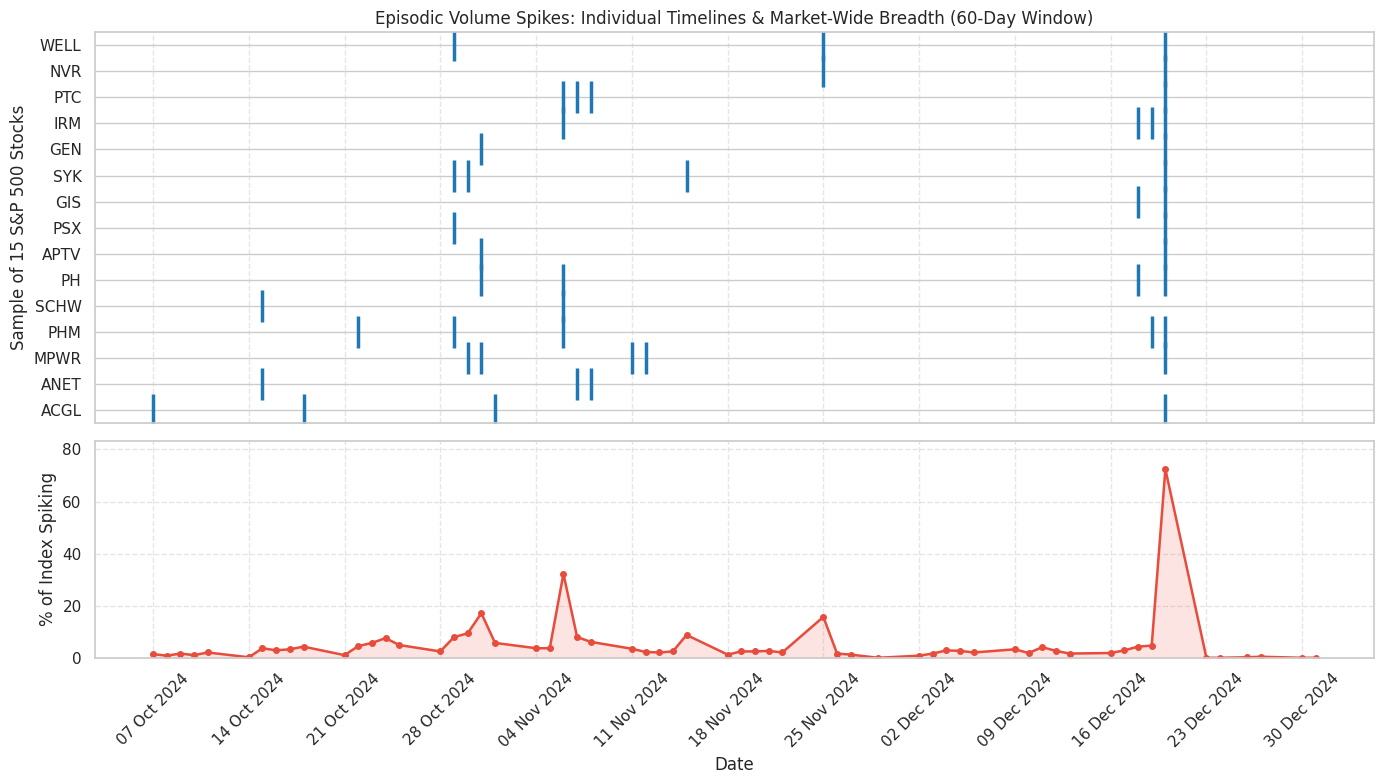

In [47]:
# Chart: barcode plot of high-volume days for a sample of shares (top) and the percentage of the
# index spiking on each day (bottom), for the final 60 sessions.
event_window = event.loc[window_dates]

# Pick a sample of 15 shares to show how individual spikes come and go
rng = np.random.default_rng(42)
sample_shares = rng.choice(event_window.columns, 15, replace=False)

# Two panels: individual shares on top, market breadth below
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                               gridspec_kw={'height_ratios': [1.8, 1]})

# Top panel: one row per share with a mark on each high-volume day
for i, share in enumerate(sample_shares):
    # Dates when an event happened
    event_dates = event_window.index[event_window[share]]
    ax1.scatter(event_dates, [i] * len(event_dates), marker='|', s=500,
                color='#1f77b4', linewidth=2.5)

ax1.set_yticks(range(len(sample_shares)))
ax1.set_yticklabels(sample_shares)
ax1.set_ylabel("Sample of 15 S&P 500 Stocks")
ax1.set_title("Episodic Volume Spikes: Individual Timelines & Market-Wide Breadth (60-Day Window)")
ax1.grid(True, axis='x', linestyle='--', alpha=0.5)
ax1.set_ylim(-0.5, len(sample_shares) - 0.5)

# Bottom panel: % of all shares with a high-volume day on each date
breadth_window = event_window.mean(axis=1) * 100
ax2.plot(breadth_window.index, breadth_window.values, color='#e74c3c', lw=1.8, marker='o', markersize=4)
ax2.fill_between(breadth_window.index, breadth_window.values, color='#e74c3c', alpha=0.15)
ax2.set_ylabel("% of Index Spiking")
ax2.set_xlabel("Date")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.set_ylim(0, max(breadth_window.values) * 1.15)

# Format the dates on the x-axis
ax2.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%d %b %Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()